## Implement cross-validation with different folds by designing custom k-fold and stratified split mechanisms, ensuring balanced class representation, and analyzing variance in model performance across iterations.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [8]:
df = pd.read_csv("heart.csv")
df = df.drop_duplicates().dropna().reset_index(drop=True)

X = df.drop(columns=["target"])
y = df["target"].astype(int)

print("Dataset Shape:", df.shape)
print("\nClass Distribution:")
print(y.value_counts())

Dataset Shape: (302, 14)

Class Distribution:
target
1    164
0    138
Name: count, dtype: int64


In [9]:
def custom_kfold(X, n_splits=5, random_state=42):
    rng = np.random.default_rng(random_state)

    indices = rng.permutation(len(X))
    folds = np.array_split(indices, n_splits)

    for i in range(n_splits):
        test_indices = folds[i]
        train_indices = np.concatenate(
            [folds[j] for j in range(n_splits) if j != i]
        )

        yield train_indices, test_indices

In [10]:
def custom_stratified_kfold(X, y, n_splits=5, random_state=42):
    rng = np.random.default_rng(random_state)

    class_folds = []

    for class_value in np.unique(y):
        class_indices = np.where(y.to_numpy() == class_value)[0]
        rng.shuffle(class_indices)

        class_folds.append(np.array_split(class_indices, n_splits))

    for i in range(n_splits):
        test_indices = np.concatenate(
            [folds[i] for folds in class_folds]
        )

        all_indices = np.arange(len(X))
        train_indices = np.setdiff1d(all_indices, test_indices)

        yield train_indices, test_indices

In [11]:
def evaluate_cv(split_function, n_splits, split_name):
    results = []

    for fold, (train_idx, test_idx) in enumerate(
        split_function(X, n_splits=n_splits), start=1
    ):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        model = RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )

        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        results.append({
            "Method": split_name,
            "Folds": n_splits,
            "Fold": fold,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(y_test, predictions, zero_division=0),
            "Recall": recall_score(y_test, predictions, zero_division=0),
            "F1 Score": f1_score(y_test, predictions, zero_division=0),
            "Class 0": int((y_test == 0).sum()),
            "Class 1": int((y_test == 1).sum())
        })

    return results

In [12]:
all_results = []

for n_splits in [3, 5, 10]:
    random_state = 42

    custom_results = evaluate_cv(
        lambda X, n_splits: custom_kfold(
            X, n_splits=n_splits, random_state=random_state
        ),
        n_splits,
        "Custom K-Fold"
    )

    stratified_results = evaluate_cv(
        lambda X, n_splits: custom_stratified_kfold(
            X, y, n_splits=n_splits, random_state=random_state
        ),
        n_splits,
        "Custom Stratified K-Fold"
    )

    all_results.extend(custom_results)
    all_results.extend(stratified_results)

results_df = pd.DataFrame(all_results)

display(results_df.round(4))

,Method,Folds,Fold,Accuracy,Precision,Recall,F1 Score,Class 0,Class 1
0,Custom K-Fold,3,1,0.8119,0.7778,0.9074,0.8376,47,54
1,Custom K-Fold,3,2,0.8218,0.8125,0.8125,0.8125,53,48
2,Custom K-Fold,3,3,0.8300,0.9091,0.8065,0.8547,38,62
3,Custom Stratified K-Fold,3,1,0.8911,0.8929,0.9091,0.9009,46,55
4,Custom Stratified K-Fold,3,2,0.7624,0.7385,0.8727,0.8000,46,55
5,Custom Stratified K-Fold,3,3,0.8500,0.8679,0.8519,0.8598,46,54
6,Custom K-Fold,5,1,0.8197,0.7500,0.9677,0.8451,30,31
7,Custom K-Fold,5,2,0.8033,0.7941,0.8438,0.8182,29,32
8,Custom K-Fold,5,3,0.8167,0.8667,0.7879,0.8254,27,33
9,Custom K-Fold,5,4,0.8667,0.8000,0.9655,0.8750,31,29


In [13]:
class_balance = results_df[
    ["Method", "Folds", "Fold", "Class 0", "Class 1"]
]

display(class_balance)

,Method,Folds,Fold,Class 0,Class 1
0,Custom K-Fold,3,1,47,54
1,Custom K-Fold,3,2,53,48
2,Custom K-Fold,3,3,38,62
3,Custom Stratified K-Fold,3,1,46,55
4,Custom Stratified K-Fold,3,2,46,55
5,Custom Stratified K-Fold,3,3,46,54
6,Custom K-Fold,5,1,30,31
7,Custom K-Fold,5,2,29,32
8,Custom K-Fold,5,3,27,33
9,Custom K-Fold,5,4,31,29


In [14]:
summary = results_df.groupby(["Method", "Folds"]).agg(
    Mean_Accuracy=("Accuracy", "mean"),
    Accuracy_Variance=("Accuracy", "var"),
    Accuracy_Std=("Accuracy", "std"),
    Mean_Precision=("Precision", "mean"),
    Mean_Recall=("Recall", "mean"),
    Mean_F1=("F1 Score", "mean")
).reset_index()

display(summary.round(4))

,Method,Folds,Mean_Accuracy,Accuracy_Variance,Accuracy_Std,Mean_Precision,Mean_Recall,Mean_F1
0,Custom K-Fold,3,0.8212,0.0001,0.0091,0.8331,0.8421,0.8349
1,Custom K-Fold,5,0.8346,0.0009,0.0299,0.8361,0.8771,0.8505
2,Custom K-Fold,10,0.8276,0.0027,0.0521,0.8305,0.8668,0.8416
3,Custom Stratified K-Fold,3,0.8345,0.0043,0.0657,0.8331,0.8779,0.8536
4,Custom Stratified K-Fold,5,0.8310,0.0063,0.0793,0.8305,0.8778,0.8508
5,Custom Stratified K-Fold,10,0.8305,0.0060,0.0771,0.8402,0.8651,0.8480


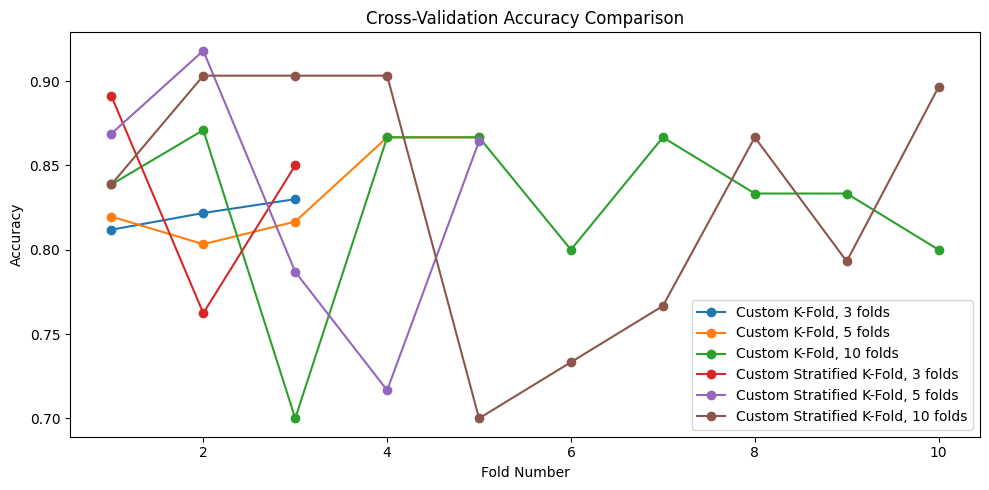

In [15]:
plt.figure(figsize=(10, 5))

for method in results_df["Method"].unique():
    for n in [3, 5, 10]:
        data = results_df[
            (results_df["Method"] == method) &
            (results_df["Folds"] == n)
        ]

        plt.plot(
            data["Fold"],
            data["Accuracy"],
            marker="o",
            label=f"{method}, {n} folds"
        )

plt.xlabel("Fold Number")
plt.ylabel("Accuracy")
plt.title("Cross-Validation Accuracy Comparison")
plt.legend()
plt.tight_layout()
plt.show()

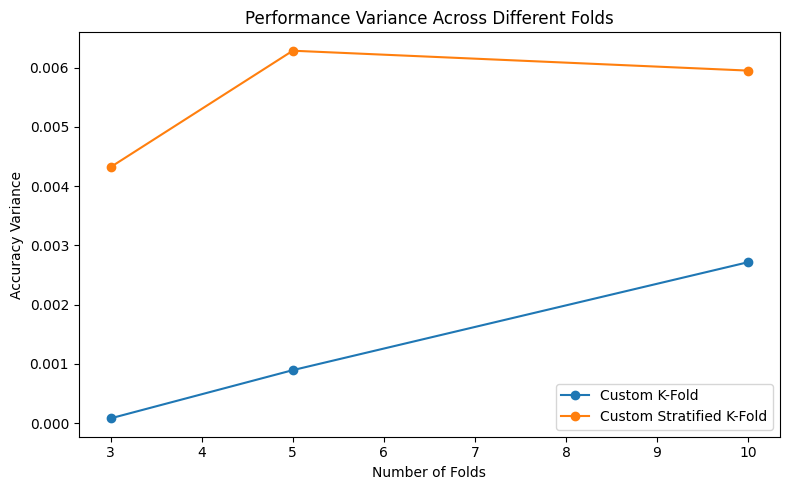

In [16]:
plt.figure(figsize=(8, 5))

for method in summary["Method"].unique():
    data = summary[summary["Method"] == method]

    plt.plot(
        data["Folds"],
        data["Accuracy_Variance"],
        marker="o",
        label=method
    )

plt.xlabel("Number of Folds")
plt.ylabel("Accuracy Variance")
plt.title("Performance Variance Across Different Folds")
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
best_result = summary.loc[summary["Mean_Accuracy"].idxmax()]

stable_result = summary.loc[summary["Accuracy_Variance"].idxmin()]

print("Best Mean Accuracy:")
print(best_result)

print("\nMost Stable Performance:")
print(stable_result)

Best Mean Accuracy:
Method               Custom K-Fold
Folds                            5
Mean_Accuracy              0.83459
Accuracy_Variance         0.000896
Accuracy_Std              0.029925
Mean_Precision            0.836096
Mean_Recall                0.87708
Mean_F1                   0.850508
Name: 1, dtype: object

Most Stable Performance:
Method               Custom K-Fold
Folds                            3
Mean_Accuracy             0.821221
Accuracy_Variance         0.000082
Accuracy_Std              0.009072
Mean_Precision            0.833123
Mean_Recall                0.84212
Mean_F1                   0.834936
Name: 0, dtype: object
